# Arc Diagram

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

Nodes are placed along a single line and connections are drawn as arcs above it. The one-dimensional layout makes node order meaningful (time, sequence, or group). Arc height shows how far apart connected nodes are.

## When to use

- Show connections where node order matters (characters by first appearance, sequential steps)
- Show co-occurrence or links within a sequence (repeated motifs, references)
- Show a cleaner network layout for small graphs

## Avoid when

- The network is large or dense (arcs overlap heavily)
- Structure such as clusters matters more than order (use a force-directed network)

## Alternatives

- Network graph
- Adjacency matrix
- Chord diagram

## Design tips

- Order the nodes meaningfully (by group, time or a clustering), since arc length depends on the order
- Encode weight with arc thickness and keep arcs semi-transparent so crossings stay legible
- Draw arcs on one side only for undirected links; use above vs. below the line to show direction

## Example

Board interlocks among 12 listed companies, where two firms are linked when they share directors (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.patches import Arc

### Data

In [2]:
chapters = [f"Co {c}" for c in "ABCDEFGHIJKL"]
refs = pd.DataFrame([(1, 3, 2), (1, 5, 1), (2, 3, 3), (2, 8, 1), (3, 4, 4), (3, 9, 2),
                     (4, 6, 2), (5, 6, 3), (5, 11, 1), (6, 7, 2), (7, 10, 3), (8, 9, 2),
                     (9, 12, 1), (10, 11, 2), (1, 12, 1), (4, 10, 1)],
                    columns=["from", "to", "refs"])  # refs = shared directors
refs.head()

,from,to,refs
0,1,3,2
1,1,5,1
2,2,3,3
3,2,8,1
4,3,4,4


### Plot

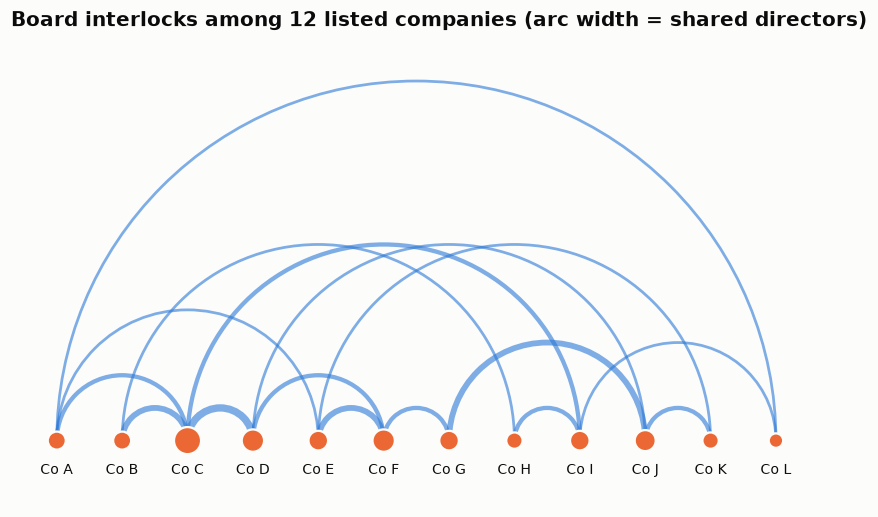

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for f, t, w in refs.itertuples(index=False):
    center, width = (f + t) / 2, abs(t - f)
    ax.add_patch(Arc((center, 0), width, width, theta1=0, theta2=180,
                     color=PALETTE[0], linewidth=0.8 + 1.0 * w, alpha=0.6))
strength = refs.groupby("from")["refs"].sum().add(refs.groupby("to")["refs"].sum(), fill_value=0)
xs = np.arange(1, 13)
ax.scatter(xs, np.zeros(12), s=[40 + 25 * strength.get(i, 0) for i in xs], color=PALETTE[1],
           zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
for x, c in zip(xs, chapters):
    ax.text(x, -0.35, c, ha="center", va="top", fontsize=9)
ax.set_xlim(0.3, 12.7)
ax.set_ylim(-1, 6.2)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Board interlocks among 12 listed companies (arc width = shared directors)")
fig.tight_layout()
plt.show()

## How to read it

Each arc joins two companies that share directors, and thicker arcs mean more shared seats. Larger dots are the most connected boards, where governance influence concentrates.

---
Standalone script: [`arc_diagram.py`](arc_diagram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)